# Cloudinary update example

When using the [Video Manager Powered by Cloudinary](https://techdocs.akamai.com/property-mgr/docs/video-manager-cloudinary) behavior for serving optimized videos, a new *feature* can now be enabled via the **PMUSER_CLD_EW** variable in your delivery configuration. When set to **cloudinaryProd**, an EdgeWorker will be used in the backend to pull the videos from the Cloudinary backend. 

> It's an EdgeWorker running in the Akamai backend; customers are not being billed for it.

The main difference is that videos are now also cached in the customer's CDN delivery setup; this wasn't the case before this PMUSER variable was introduced. But because it's now cached in two locations, we need to purge both entries, the orange Akamai locations in the image below:

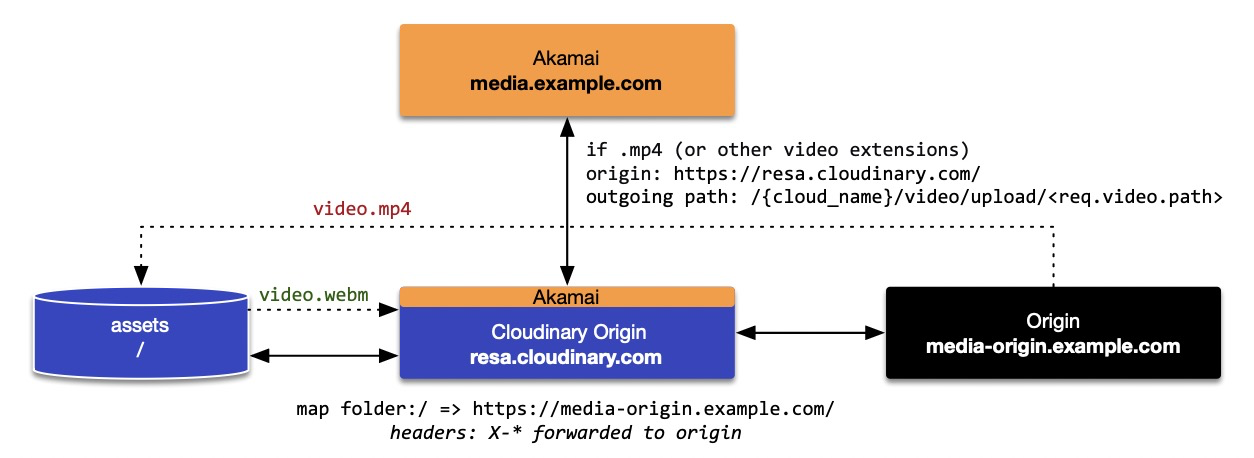

> This *purge* only needs to happen when you're updating an existing video. A new video will automatically be pulled in from the origin via the *Auto Upload Mapping* feature of Cloudinary and cached in both Akamai layers.   

## Credentials

This notebook requires credentials for Akamai and Cloudinary.

### Cloudinary

To use the Cloudinary admin api we need to set 3 environment variables:  

1. CLOUDINARY_API_KEY
2. CLOUDINARY_API_SECRET
3. CLOUDINARY_CLOUD_NAME

This information can be found in the Cloudinary portal under *settings => API Keys*
> To limit the *power* of this  API Key, make sure to only assign the purge role in Cloudinary. Roles have been introduced in 2026, make sure your Cloudinary environment has already been updated

### Set Up EdgeGrid Session

Let's first set up an EdgeGrid session using information from the `~/.edgerc` file. The correct *section* can be set via `export AKAMAI_EDGEGRID_SECTION=section`; otherwise, `default` is going to be used.

Make sure your API user has the [purge permissions](https://techdocs.akamai.com/purge-cache/reference/api-get-started).

This notebook supports the `AccountSwitchKey` option, which can be set via `export AKAMAI_ACCOUNT_SWITCH_KEY="1-2345:A-BCDE"`

In [ ]:
import json
import os

import requests
from akamai.edgegrid import EdgeGridAuth, EdgeRc

edgerc_path = os.path.expanduser("~/.edgerc")

if not os.path.exists(edgerc_path):
    raise FileNotFoundError(f"Could not find .edgerc at {edgerc_path}")

section = os.getenv("AKAMAI_EDGEGRID_SECTION", "default")
account_switch_key = os.getenv("AKAMAI_ACCOUNT_SWITCH_KEY")

edgerc = EdgeRc(edgerc_path)
host = edgerc.get(section, "host")

session = requests.Session()
session.auth = EdgeGridAuth.from_edgerc(edgerc, section)
session.headers.update({
    "Accept": "application/json",
    "Content-Type": "application/json",
})

base_url = f"https://{host}"
print(f"EdgeGrid session configured for host: {host}")

if account_switch_key:
    print(f"Using AccountSwitchKey: {account_switch_key}")

## Get list of videos

Just get a list of 100 videos for this demo, you can select the number of the video you want to purge.

In [ ]:
import os

import cloudinary
import cloudinary.api

required_cloudinary_vars = (
    "CLOUDINARY_CLOUD_NAME",
    "CLOUDINARY_API_KEY",
    "CLOUDINARY_API_SECRET",
)
missing_cloudinary_vars = [
    name for name in required_cloudinary_vars if not os.getenv(name)
]

if missing_cloudinary_vars:
    raise EnvironmentError(
        "Set these environment variables before running this cell: "
        + ", ".join(missing_cloudinary_vars)
    )

cloudinary.config(
    cloud_name=os.environ["CLOUDINARY_CLOUD_NAME"],
    api_key=os.environ["CLOUDINARY_API_KEY"],
    api_secret=os.environ["CLOUDINARY_API_SECRET"],
    secure=True,
)

resource_response = cloudinary.api.resources(
    resource_type="video",
    type="upload",
    max_results=100,
)
video_assets = resource_response.get("resources", [])

if not video_assets:
    print("No uploaded video assets were found.")
else:
    print(f"Found {len(video_assets)} uploaded video asset(s):")
    for asset_number, asset in enumerate(video_assets, start=1):
        print(
            f"{asset_number}: {asset['public_id']}"
            f" | format={asset.get('format', 'unknown')}"
            f" | created={asset.get('created_at', 'unknown')}"
        )

## Delete video

Now delete this video from the assets database and Cloudinary Akamai setup and purge from the Akamai Environment of the customer. In the delivery configuration we added a *Cache Tag* option based on the [public id](https://cloudinary.com/documentation/ts_asset_id_vs_public_id#banner). Public id just being origin path without extension and starting /. So make sure to set this cache-tag in your delivery configuration or build the url yourself and use that for purging.

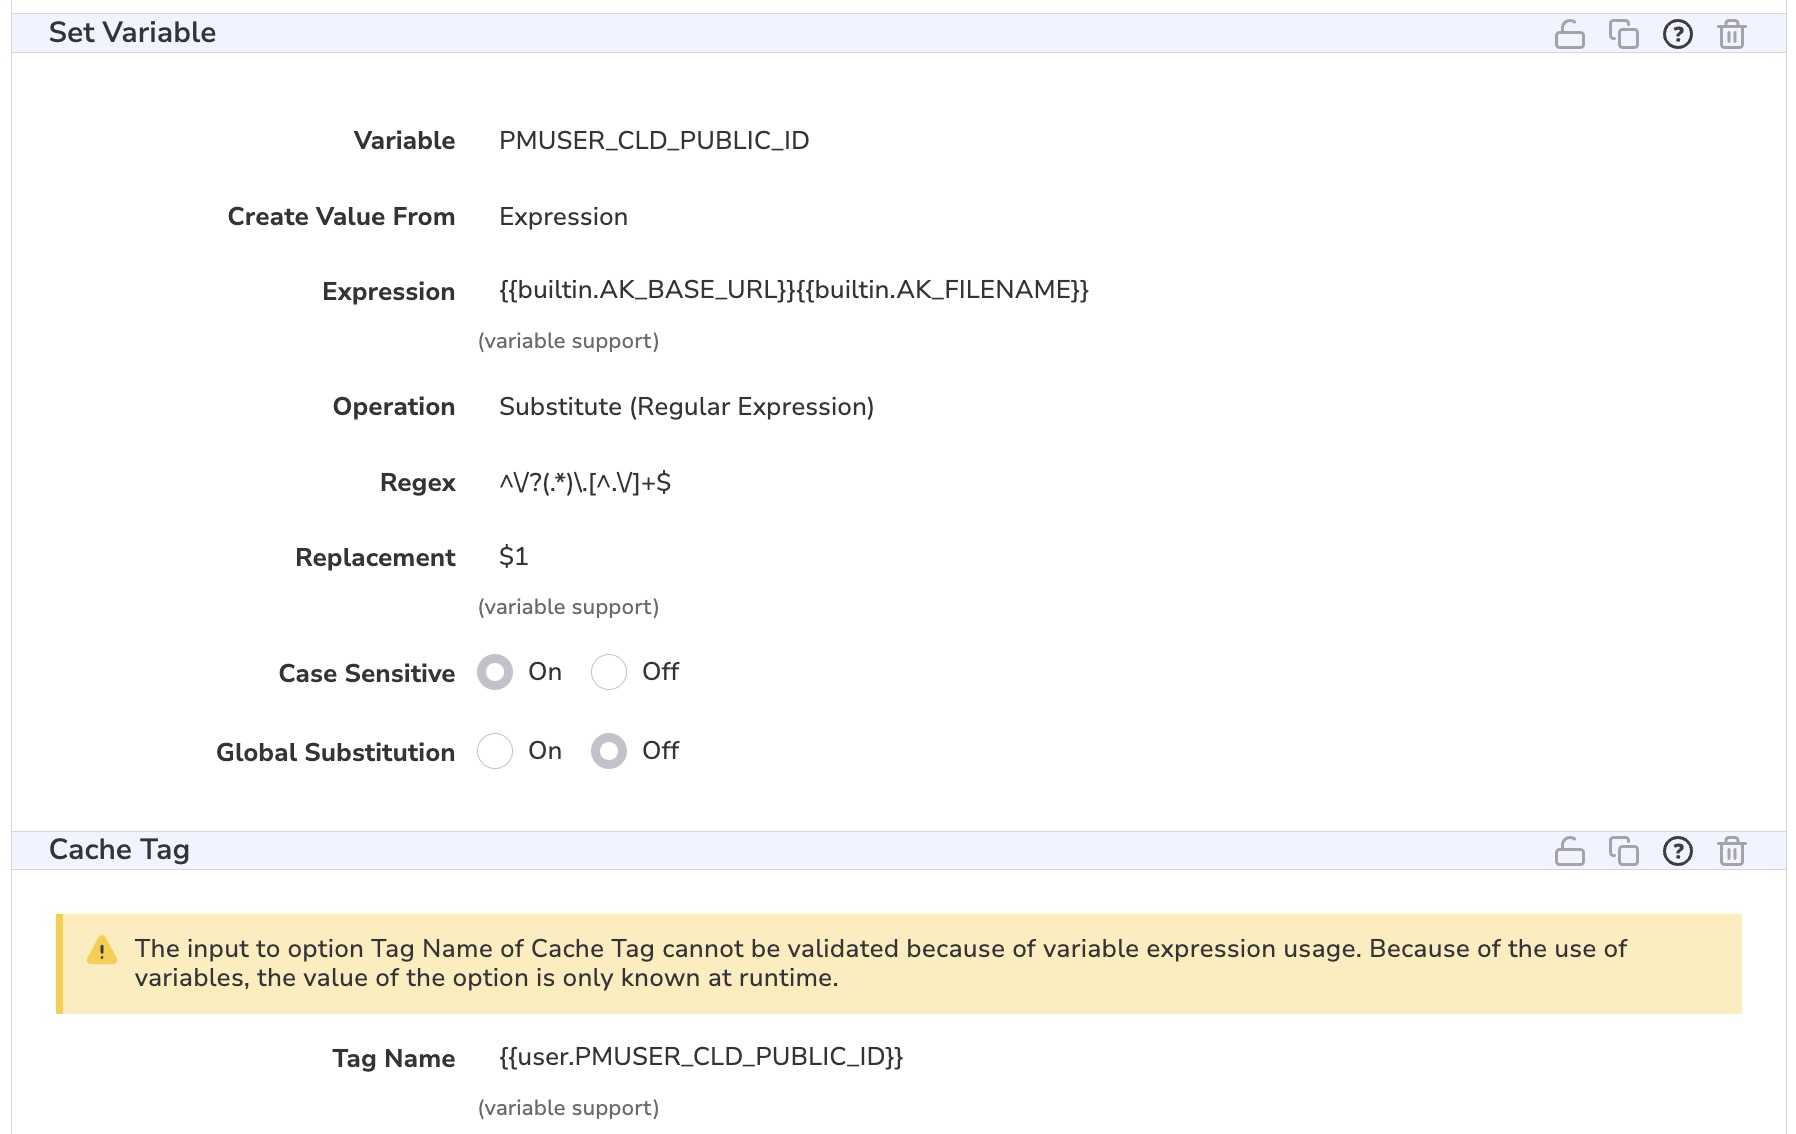

But when using this cache-tag we can simply purge Cloudinary and Akamai using the same public_id.

In [ ]:
if not video_assets:
    print("Nothing to delete.")
else:
    selection = input(
        f"Enter the number of the video to delete (1-{len(video_assets)}): "
    ).strip()

    try:
        selected_asset = video_assets[int(selection) - 1]
    except (ValueError, IndexError):
        raise ValueError("Enter a number corresponding to one of the listed assets.")

    public_id = selected_asset["public_id"]
    confirmation = input(
        f'Type DELETE to purge cache-tag "{public_id}" and remove the Cloudinary asset: '
    ).strip()

    if confirmation != "DELETE":
        print("Deletion cancelled.")
    else:
        ccu_url = f"{base_url}/ccu/v3/invalidate/tag/staging"
        ccu_response = session.post(
            ccu_url,
            json={"objects": [public_id]},
        )
        ccu_response.raise_for_status()
        print(f"Akamai staging cache-tag purge response: {ccu_response.json()}")

        delete_response = cloudinary.api.delete_resources(
            [public_id],
            resource_type="video",
            type="upload",
            invalidate=True,
        )
        print(f"Cloudinary response: {delete_response}")